In [ ]:
import os
import random
import shutil
import numpy as np
import librosa
import soundfile as sf
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, roc_curve, auc,
    confusion_matrix, classification_report,
    precision_recall_curve, average_precision_score
)
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks, regularizers
import matplotlib.pyplot as plt
from tqdm import tqdm
import seaborn as sns
import pandas as pd

SAMPLE_RATE = 16000
N_MELS = 128
N_FFT = 2048
HOP_LENGTH = 512
MAX_SECONDS = 4.0
MAX_LEN = int(SAMPLE_RATE * MAX_SECONDS)
SUBSET_PER_CLASS = 15000
BATCH_SIZE = 32
NUM_EPOCHS = 50
RANDOM_SEED = 42

L2_REG = 0.001
DROPOUT_RATE = 0.5
INITIAL_LR = 3e-5

OUT_DIR = "./spectrogram_detection"
os.makedirs(OUT_DIR, exist_ok=True)


os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'


In [ ]:
DATASET_ROOT = "/root/.cache/kagglehub/datasets/abdallamohamed312/ready-to-input-for-training/versions/1/combined_folder"

if not os.path.exists(DATASET_ROOT):
    print("Dataset not found.")
    import kagglehub
    dataset_path = kagglehub.dataset_download('abdallamohamed312/ready-to-input-for-training')
    DATASET_ROOT = os.path.join(dataset_path, 'combined_folder')
    print(f"Dataset downloaded to: {DATASET_ROOT}")
else:
    print("Dataset found")

real_dir = Path(DATASET_ROOT) / "real"
fake_dir = Path(DATASET_ROOT) / "fake"
subset_dir = Path(OUT_DIR) / "subset"
spec_dir = Path(OUT_DIR) / "spectrograms"

subset_dir.mkdir(parents=True, exist_ok=True)
spec_dir.mkdir(parents=True, exist_ok=True)

print(f"   Real audio dir: {real_dir}")
print(f"   Fake audio dir: {fake_dir}")
print(f"   Subset dir: {subset_dir}")
print(f"   Spectrogram dir: {spec_dir}")

Dataset not found.
Using Colab cache for faster access to the 'ready-to-input-for-training' dataset.
Dataset downloaded to: /kaggle/input/ready-to-input-for-training/combined_folder
   Real audio dir: /kaggle/input/ready-to-input-for-training/combined_folder/real
   Fake audio dir: /kaggle/input/ready-to-input-for-training/combined_folder/fake
   Subset dir: spectrogram_detection/subset
   Spectrogram dir: spectrogram_detection/spectrograms


In [ ]:
def create_subset(src, dst, n):
    dst.mkdir(parents=True, exist_ok=True)
    files = list(src.glob("*.*"))
    random.shuffle(files)

    copied = 0
    for f in files[:min(n, len(files))]:
        try:
            shutil.copy(f, dst / f.name)
            copied += 1
        except Exception as e:
            print(f"Error copying {f.name}: {e}")

    return copied

n_real = create_subset(real_dir, subset_dir / "real", SUBSET_PER_CLASS)
n_fake = create_subset(fake_dir, subset_dir / "fake", SUBSET_PER_CLASS)

print(f"Subset created:")
print(f"   Real: {n_real:,} files")
print(f"   Fake: {n_fake:,} files")
print(f"   Total: {n_real + n_fake:,} files")

Subset created:
   Real: 15,000 files
   Fake: 15,000 files
   Total: 30,000 files


In [ ]:
def extract_mel_spectrogram(audio_path, target_sr=SAMPLE_RATE, n_mels=N_MELS,
                            n_fft=N_FFT, hop_length=HOP_LENGTH, max_len=MAX_LEN):

    try:
        y, sr = librosa.load(audio_path, sr=target_sr, mono=True)

        if len(y) > max_len:
            y = y[:max_len]
        else:
            y = np.pad(y, (0, max_len - len(y)), mode='constant')

        mel_spec = librosa.feature.melspectrogram(
            y=y,
            sr=target_sr,
            n_mels=n_mels,
            n_fft=n_fft,
            hop_length=hop_length,
            power=2.0
        )

        log_mel_spec = librosa.power_to_db(mel_spec, ref=np.max)

        log_mel_spec = (log_mel_spec - log_mel_spec.min()) / (log_mel_spec.max() - log_mel_spec.min() + 1e-8)

        return log_mel_spec.astype(np.float32)

    except Exception as e:
        print(f"Error processing {audio_path}: {e}")
        return None

print("Extracting spectrograms...")

for label in ["real", "fake"]:
    src = subset_dir / label
    dst = spec_dir / label
    dst.mkdir(parents=True, exist_ok=True)

    files = list(src.glob("*.*"))

    for f in tqdm(files, desc=f"Processing {label}"):
        out_path = dst / (f.stem + ".npy")

        if out_path.exists():
            continue

        spec = extract_mel_spectrogram(f)

        if spec is not None:
            np.save(out_path, spec)

print("")
print("Spectrogram extraction complete")

sample_files = list((spec_dir / "real").glob("*.npy"))
if sample_files:
    sample_spec = np.load(sample_files[0])
    print(f"   Sample spectrogram shape: {sample_spec.shape}")
    print(f"   Value range: [{sample_spec.min():.3f}, {sample_spec.max():.3f}]")

Extracting spectrograms...


Processing fake: 100%|██████████| 15000/15000 [02:33<00:00, 97.92it/s] 


Spectrogram extraction complete
   Sample spectrogram shape: (128, 126)
   Value range: [0.000, 1.000]


In [ ]:
def augment_spectrogram(spec, augment=True):

    if not augment:
        return spec

    spec = spec.copy()

    if np.random.rand() < 0.5:
        num_masks = np.random.randint(1, 3)
        for _ in range(num_masks):
            mask_width = np.random.randint(5, 20)
            start_col = np.random.randint(0, max(1, spec.shape[1] - mask_width))
            spec[:, start_col:start_col + mask_width] = 0

    if np.random.rand() < 0.5:
        num_masks = np.random.randint(1, 3)
        for _ in range(num_masks):
            mask_height = np.random.randint(3, 15)
            start_row = np.random.randint(0, max(1, spec.shape[0] - mask_height))
            spec[start_row:start_row + mask_height, :] = 0

    if np.random.rand() < 0.3:
        noise_level = np.random.uniform(0.0005, 0.002)
        noise = np.random.normal(0, noise_level, spec.shape)
        spec = spec + noise

    if np.random.rand() < 0.2:
        shift_amount = np.random.randint(-10, 10)
        spec = np.roll(spec, shift_amount, axis=1)

    return np.clip(spec, 0, 1)

In [ ]:

def load_spectrogram_data(base_dir):
    files, labels = [], []

    for label_name, label_val in [("real", 1), ("fake", 0)]:
        label_dir = base_dir / label_name

        if not label_dir.exists():
            print(f"WARNING: {label_dir} does not exist!")
            continue

        spec_files = list(label_dir.glob("*.npy"))
        print(f"   Found {len(spec_files)} files in {label_name}/")

        for spec_file in spec_files:
            try:
                test_load = np.load(spec_file)
                if test_load.shape[0] != N_MELS:
                    print(f"Skipping {spec_file.name}: wrong shape {test_load.shape}")
                    continue
                if np.isnan(test_load).any() or np.isinf(test_load).any():
                    print(f"Skipping {spec_file.name}: contains NaN/Inf")
                    continue

                files.append(str(spec_file))
                labels.append(label_val)
            except Exception as e:
                print(f"Error loading {spec_file.name}: {e}")
                continue

    return files, labels

files, labels = load_spectrogram_data(spec_dir)
print(f"\n Loaded {len(files)} valid spectrograms")
print(f"   Real: {sum(labels)} samples")
print(f"   Fake: {len(labels) - sum(labels)} samples")

real_count = sum(labels)
fake_count = len(labels) - sum(labels)
if real_count == 0 or fake_count == 0:
    print("CRITICAL: One class has no samples!")
elif abs(real_count - fake_count) / len(labels) > 0.2:
    print(f"WARNING: Class imbalance detected!")
    print(f"   Real/Fake ratio: {real_count/fake_count:.2f}")

train_files, temp_files, train_labels, temp_labels = train_test_split(
    files, labels, test_size=0.4, random_state=42, stratify=labels
)
val_files, test_files, val_labels, test_labels = train_test_split(
    temp_files, temp_labels, test_size=0.5, random_state=42, stratify=temp_labels
)

print(f"\n Dataset split:")
print(f"   Train: {len(train_files):,} ({sum(train_labels)} real, {len(train_labels)-sum(train_labels)} fake)")
print(f"   Val:   {len(val_files):,} ({sum(val_labels)} real, {len(val_labels)-sum(val_labels)} fake)")
print(f"   Test:  {len(test_files):,} ({sum(test_labels)} real, {len(test_labels)-sum(test_labels)} fake)")

   Found 15000 files in real/
   Found 15000 files in fake/

 Loaded 30000 valid spectrograms
   Real: 15000 samples
   Fake: 15000 samples

 Dataset split:
   Train: 18,000 (9000 real, 9000 fake)
   Val:   6,000 (3000 real, 3000 fake)
   Test:  6,000 (3000 real, 3000 fake)


In [ ]:
class SpectrogramGenerator(tf.keras.utils.Sequence):

    def __init__(self, file_paths, labels, batch_size=32, augment=False, shuffle=True):
        self.file_paths = file_paths
        self.labels = labels
        self.batch_size = batch_size
        self.augment = augment
        self.shuffle = shuffle
        self.indices = np.arange(len(self.file_paths))
        self.on_epoch_end()

    def __len__(self):
        return len(self.file_paths) // self.batch_size

    def __getitem__(self, index):
        batch_indices = self.indices[index * self.batch_size:(index + 1) * self.batch_size]
        batch_files = [self.file_paths[i] for i in batch_indices]
        batch_labels = [self.labels[i] for i in batch_indices]

        X, y = self._load_batch(batch_files, batch_labels)
        return X, y

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

    def _load_batch(self, batch_files, batch_labels):
        X = []
        y = []

        for file_path, label in zip(batch_files, batch_labels):
            try:
                spec = np.load(file_path)


                spec_min = spec.min()
                spec_max = spec.max()

                if spec_max > spec_min:
                    spec = (spec - spec_min) / (spec_max - spec_min)
                else:
                    spec = np.zeros_like(spec)

                spec = np.clip(spec, 0.0, 1.0)

                if np.isnan(spec).any() or np.isinf(spec).any():
                    print(f"Skipping bad spec: {file_path}")
                    continue

                if self.augment:
                    spec = augment_spectrogram(spec, augment=True)

                spec = np.expand_dims(spec, axis=-1)

                X.append(spec)
                y.append(label)

            except Exception as e:
                print(f"Error loading {file_path}: {e}")
                continue

        if len(X) == 0:
            dummy = np.random.rand(128, 251, 1).astype(np.float32) * 0.5
            X = [dummy] * self.batch_size
            y = [0, 1] * (self.batch_size // 2)

        X = np.array(X, dtype=np.float32)
        y = np.array(y, dtype=np.float32)

        X = np.nan_to_num(X, nan=0.0, posinf=1.0, neginf=0.0)
        X = np.clip(X, 0.0, 1.0)

        return X, y




print("\n Creating FIXED generators with forced normalization...")

train_gen = SpectrogramGenerator(
    train_files, train_labels,
    batch_size=BATCH_SIZE,
    augment=True,
    shuffle=True
)

val_gen = SpectrogramGenerator(
    val_files, val_labels,
    batch_size=BATCH_SIZE,
    augment=True,
    shuffle=True
)

test_gen = SpectrogramGenerator(
    test_files, test_labels,
    batch_size=BATCH_SIZE,
    augment=True,
    shuffle=True
)


print("\n Validating fixed data...")
sample_X, sample_y = train_gen[0]

print(f"Batch shape: {sample_X.shape}")
print(f"Batch min/max: {sample_X.min():.6f} / {sample_X.max():.6f}")
print(f"Batch mean: {sample_X.mean():.6f}")
print(f"Batch std: {sample_X.std():.6f}")

if sample_X.min() < -0.01 or sample_X.max() > 1.01:
    print("STILL BROKEN: Values outside [0, 1]!")
else:
    print("Data is now in [0, 1] range")




print("CHECKING IF SPECTROGRAMS NEED REGENERATION")

raw_spec = np.load(train_files[0])

print(f"\nRaw spectrogram (from file):")
print(f"  Shape: {raw_spec.shape}")
print(f"  Min: {raw_spec.min():.6f}")
print(f"  Max: {raw_spec.max():.6f}")
print(f"  Mean: {raw_spec.mean():.6f}")
print(f"  Std: {raw_spec.std():.6f}")

if raw_spec.min() < -0.1 or raw_spec.max() > 1.1:
    print("\n CRITICAL: Raw spectrograms are NOT in [0, 1]!")
    print("   Your spectrograms were saved INCORRECTLY.")
    print("\n   OPTIONS:")
    print("   1. Use the fixed generator above (normalizes on-the-fly)")
    print("   2. OR regenerate all spectrograms with proper normalization")
    print("\n   The generator fix is FASTER, but regeneration is CLEANER.")
elif raw_spec.max() < 0.1:
    print("\n  WARNING: Spectrograms are very dark (max < 0.1)")
    print("   This might cause learning issues.")
else:
    print("\n Raw spectrograms look okay")




 Creating FIXED generators with forced normalization...

 Validating fixed data...
Batch shape: (32, 128, 126, 1)
Batch min/max: 0.000000 / 1.000000
Batch mean: 0.153807
Batch std: 0.216986
Data is now in [0, 1] range
CHECKING IF SPECTROGRAMS NEED REGENERATION

Raw spectrogram (from file):
  Shape: (128, 126)
  Min: 0.000000
  Max: 1.000000
  Mean: 0.080559
  Std: 0.167673

 Raw spectrograms look okay


In [ ]:
def residual_block(x, filters, kernel_size=3, stride=1, l2_reg=0.0015, dropout=0.0):
    shortcut = x

    x = layers.Conv2D(filters, kernel_size, strides=stride, padding='same',
                      use_bias=False, kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    x = layers.Conv2D(filters, kernel_size, strides=1, padding='same',
                      use_bias=False, kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)

    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, strides=stride, padding='same',
                                use_bias=False, kernel_regularizer=regularizers.l2(l2_reg))(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    x = layers.Add()([x, shortcut])
    x = layers.Activation('relu')(x)

    if dropout > 0:
        x = layers.Dropout(dropout)(x)

    return x

def attention_block(x, filters, l2_reg=0.0015):
    gap = layers.GlobalAveragePooling2D()(x)
    attention = layers.Dense(filters // 8, activation='relu',
                            kernel_regularizer=regularizers.l2(l2_reg))(gap)
    attention = layers.Dense(filters, activation='sigmoid',
                            kernel_regularizer=regularizers.l2(l2_reg))(attention)
    attention = layers.Reshape((1, 1, filters))(attention)
    x = layers.Multiply()([x, attention])
    return x

def build_specrnet_robust(input_shape, l2_reg=0.001, dropout_rate=0.5):

    inputs = layers.Input(shape=input_shape)

    x = layers.Conv2D(32, 7, strides=2, padding='same', use_bias=False,
                     kernel_regularizer=regularizers.l2(l2_reg))(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)

    x = residual_block(x, 32, stride=1, l2_reg=l2_reg, dropout=0.0)
    x = residual_block(x, 32, stride=1, l2_reg=l2_reg, dropout=0.0)

    x = residual_block(x, 64, stride=2, l2_reg=l2_reg, dropout=0.0)
    x = residual_block(x, 64, stride=1, l2_reg=l2_reg, dropout=dropout_rate*0.5)

    x = residual_block(x, 128, stride=2, l2_reg=l2_reg, dropout=0.0)
    x = residual_block(x, 128, stride=1, l2_reg=l2_reg, dropout=dropout_rate*0.7)

    x = residual_block(x, 256, stride=2, l2_reg=l2_reg, dropout=0.0)
    x = residual_block(x, 256, stride=1, l2_reg=l2_reg, dropout=dropout_rate)

    x = attention_block(x, 256, l2_reg=l2_reg)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout_rate)(x)

    x = layers.Dense(128, activation='relu',
                    kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout_rate)(x)

    x = layers.Dense(64, activation='relu',
                    kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout_rate*0.5)(x)

    outputs = layers.Dense(1, activation='sigmoid',
                          kernel_regularizer=regularizers.l2(l2_reg),
                          bias_initializer=tf.keras.initializers.Constant(0.0))(x)

    model = models.Model(inputs, outputs, name='SpecRNet_Robust')
    return model

sample_spec = np.load(train_files[0])
SPEC_SHAPE = sample_spec.shape + (1,)
print(f"\nSpectrogram shape: {SPEC_SHAPE}")

model = build_specrnet_robust(
    input_shape=SPEC_SHAPE,
    l2_reg=L2_REG,
    dropout_rate=DROPOUT_RATE
)

model.summary()





Spectrogram shape: (128, 126, 1)


Model: "SpecRNet_Robust"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 126,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 63,    │      1,568 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64, 63,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 64, 63,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 32, 32,    │          0 │ activation[0][0]  │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 32, 32,    │      9,216 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │      9,216 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ max_pooling2d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 32, 32,    │          0 │ add[0][0]         │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32,    │      9,216 │ activation_2[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │      9,216 │ activation_3[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_4[0][0]  

 Total params: 2,859,201 (10.91 MB)

 Trainable params: 2,854,017 (10.89 MB)

 Non-trainable params: 5,184 (20.25 KB)

In [ ]:
optimizer = optimizers.Adam(learning_rate=3e-5, clipnorm=1.0)

model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc'),
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall')]
)

checkpoint = callbacks.ModelCheckpoint(
    os.path.join(OUT_DIR, 'specrnet_fixed.keras'),
    monitor='val_auc', mode='max', save_best_only=True, verbose=1
)

early_stop = callbacks.EarlyStopping(
    monitor='val_loss', patience=10, restore_best_weights=True, verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=4, min_lr=1e-7, verbose=1
)


class DiagnosticCallback(callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        train_acc = logs.get('accuracy', 0)
        val_acc = logs.get('val_accuracy', 0)

        tp = logs.get('val_tp', 0)
        tn = logs.get('val_tn', 0)
        fp = logs.get('val_fp', 0)
        fn = logs.get('val_fn', 0)

        total = tp + tn + fp + fn
        pred_real = tp + fp
        pred_fake = tn + fn

        print(f"\n{'='*70}")
        print(f"Epoch {epoch+1} Diagnosis:")
        print(f"  Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")

        if total > 0:
            print(f"  Predictions: {pred_real}/{total} Real ({pred_real/total*100:.1f}%), "
                  f"{pred_fake}/{total} Fake ({pred_fake/total*100:.1f}%)")
            print(f"  Confusion: TP={tp:.0f}, TN={tn:.0f}, FP={fp:.0f}, FN={fn:.0f}")

            if val_acc < 0.55:
                print(f"   CRITICAL: Val accuracy {val_acc:.1%} is near random!")
                if pred_real > total * 0.9:
                    print(f"     → Model predicting ALL Real")
                elif pred_fake > total * 0.9:
                    print(f"     → Model predicting ALL Fake")
                else:
                    print(f"     → Model making random predictions")
            elif val_acc < 0.65:
                print(f"   Poor accuracy - model struggling to learn")
            elif val_acc > 0.75:
                print(f"  Good accuracy!")


diagnostic = DiagnosticCallback()



In [ ]:
print("STARTING  TRAINING")
print(f"Model: SpecRNet CNN")

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=50,
    callbacks=[checkpoint, early_stop, reduce_lr, diagnostic],
    verbose=1
)

print("TRAINING COMPLETE")


STARTING  TRAINING
Model: SpecRNet CNN
Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


562/562 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.5039 - auc: 0.5024 - loss: 3.3593 - precision: 0.5007 - recall: 0.5086
Epoch 1: val_auc improved from -inf to 0.56776, saving model to ./spectrogram_detection/specrnet_fixed.keras

Epoch 1 Diagnosis:
  Train Acc: 0.5028 | Val Acc: 0.5261
562/562 ━━━━━━━━━━━━━━━━━━━━ 69s 86ms/step - accuracy: 0.5039 - auc: 0.5024 - loss: 3.3593 - precision: 0.5007 - recall: 0.5086 - val_accuracy: 0.5261 - val_auc: 0.5678 - val_loss: 3.1116 - val_precision: 0.5800 - val_recall: 0.1901 - learning_rate: 3.0000e-05
Epoch 2/50
562/562 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.5187 - auc: 0.5219 - loss: 3.2733 - precision: 0.5246 - recall: 0.5215
Epoch 2: val_auc improved from 0.56776 to 0.61944, saving model to ./spectrogram_detection/specrnet_fixed.keras

Epoch 2 Diagnosis:
  Train Acc: 0.5160 | Val Acc: 0.5879
562/562 ━━━━━━━━━━━━━━━━━━━━ 47s 83ms/step - accuracy: 0.5187 - auc: 0.5219 - loss: 3.2733 - precision: 0.5246 - recall: 0.5215 - val_acc

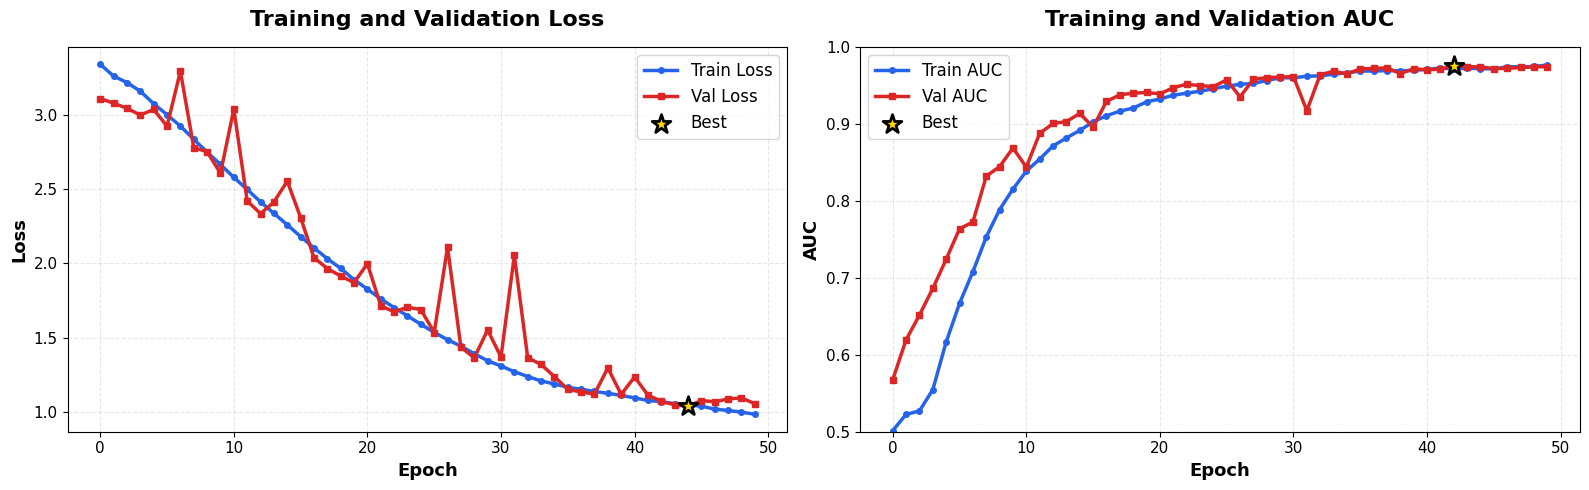

   Best Val Loss: 1.0363 at epoch 45
   Best Val AUC:  0.9752 at epoch 43


In [ ]:


def plot_training_history(history, save_path):

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    axes[0].plot(history.history['loss'], label='Train Loss',
                 color='#2563eb', linewidth=2.5, marker='o', markersize=4)
    axes[0].plot(history.history['val_loss'], label='Val Loss',
                 color='#dc2626', linewidth=2.5, marker='s', markersize=4)
    axes[0].set_title('Training and Validation Loss',
                      fontsize=16, fontweight='bold', pad=15)
    axes[0].set_xlabel('Epoch', fontsize=13, fontweight='semibold')
    axes[0].set_ylabel('Loss', fontsize=13, fontweight='semibold')
    axes[0].legend(fontsize=12, loc='best')
    axes[0].grid(True, alpha=0.3, linestyle='--')
    axes[0].tick_params(labelsize=11)

    best_epoch = np.argmin(history.history['val_loss'])
    best_loss = history.history['val_loss'][best_epoch]
    axes[0].scatter([best_epoch], [best_loss],
                    color='gold', s=200, marker='*',
                    edgecolor='black', linewidth=2,
                    zorder=5, label='Best')
    axes[0].legend(fontsize=12, loc='best')

    axes[1].plot(history.history['auc'], label='Train AUC',
                 color='#2563eb', linewidth=2.5, marker='o', markersize=4)
    axes[1].plot(history.history['val_auc'], label='Val AUC',
                 color='#dc2626', linewidth=2.5, marker='s', markersize=4)
    axes[1].set_title('Training and Validation AUC',
                      fontsize=16, fontweight='bold', pad=15)
    axes[1].set_xlabel('Epoch', fontsize=13, fontweight='semibold')
    axes[1].set_ylabel('AUC', fontsize=13, fontweight='semibold')
    axes[1].legend(fontsize=12, loc='best')
    axes[1].grid(True, alpha=0.3, linestyle='--')
    axes[1].set_ylim([0.5, 1.0])
    axes[1].tick_params(labelsize=11)

    best_epoch = np.argmax(history.history['val_auc'])
    best_auc = history.history['val_auc'][best_epoch]
    axes[1].scatter([best_epoch], [best_auc],
                    color='gold', s=200, marker='*',
                    edgecolor='black', linewidth=2,
                    zorder=5, label='Best')
    axes[1].legend(fontsize=12, loc='best')

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()


    print(f"   Best Val Loss: {min(history.history['val_loss']):.4f} at epoch {np.argmin(history.history['val_loss']) + 1}")
    print(f"   Best Val AUC:  {max(history.history['val_auc']):.4f} at epoch {np.argmax(history.history['val_auc']) + 1}")


# Use it after training
plot_training_history(history, os.path.join(OUT_DIR, 'training_history.png'))

In [ ]:
print("EVALUATING ON TEST SET")



all_preds = []
all_labels = []

for i in range(len(test_gen)):
    X_batch, y_batch = test_gen[i]
    preds_batch = model.predict(X_batch, verbose=0)
    all_preds.extend(preds_batch.flatten())
    all_labels.extend(y_batch)

y_pred_probs = np.array(all_preds)
y_true = np.array(all_labels)

print(f"Collected {len(y_pred_probs)} predictions")
print(f"Collected {len(y_true)} labels")

assert len(y_pred_probs) == len(y_true), "Mismatch in predictions and labels!"



from sklearn.metrics import (
    roc_curve, auc, confusion_matrix,
    precision_recall_curve, average_precision_score,
    classification_report
)

fpr, tpr, thresholds = roc_curve(y_true, y_pred_probs)
roc_auc = auc(fpr, tpr)

fnr = 1 - tpr
eer_threshold_idx = np.nanargmin(np.abs(fnr - fpr))
eer = fpr[eer_threshold_idx]
eer_threshold = thresholds[eer_threshold_idx]

precision, recall, pr_thresholds = precision_recall_curve(y_true, y_pred_probs)
f1_scores = 2 * (precision[:-1] * recall[:-1]) / (precision[:-1] + recall[:-1] + 1e-10)
best_f1_idx = np.argmax(f1_scores)
best_f1_threshold = pr_thresholds[best_f1_idx]
best_f1 = f1_scores[best_f1_idx]

y_pred = (y_pred_probs >= best_f1_threshold).astype(int)

cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

accuracy = (tp + tn) / (tp + tn + fp + fn)
precision_score = tp / (tp + fp) if (tp + fp) > 0 else 0
recall_score = tp / (tp + fn) if (tp + fn) > 0 else 0
f1_final = 2 * precision_score * recall_score / (precision_score + recall_score) if (precision_score + recall_score) > 0 else 0
pr_auc = average_precision_score(y_true, y_pred_probs)



print("TEST METRICS")
print(f"ROC AUC:         {roc_auc:.4f}")
print(f"PR AUC:          {pr_auc:.4f}")
print(f"EER:             {eer:.4f} (threshold: {eer_threshold:.4f})")
print(f"Best F1:         {best_f1:.4f} (threshold: {best_f1_threshold:.4f})")
print(f"\nAt Best Threshold ({best_f1_threshold:.4f}):")
print(f"  Accuracy:      {accuracy:.4f}")
print(f"  Precision:     {precision_score:.4f}")
print(f"  Recall:        {recall_score:.4f}")
print(f"  F1 Score:      {f1_final:.4f}")

n_pred_real = y_pred.sum()
n_pred_fake = len(y_pred) - n_pred_real



print(f"\nConfusion Matrix:")
print(f"                Predicted")
print(f"                Fake    Real")
print(f"  Actual Fake   {tn:5d}   {fp:5d}")
print(f"  Actual Real   {fn:5d}   {tp:5d}")

print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=['Fake', 'Real'], digits=4))





EVALUATING ON TEST SET
Collected 5984 predictions
Collected 5984 labels
TEST METRICS
ROC AUC:         0.9737
PR AUC:          0.9732
EER:             0.0872 (threshold: 0.5132)
Best F1:         0.9155 (threshold: 0.4107)

At Best Threshold (0.4107):
  Accuracy:      0.9136
  Precision:     0.8955
  Recall:        0.9365
  F1 Score:      0.9155

Confusion Matrix:
                Predicted
                Fake    Real
  Actual Fake    2666     327
  Actual Real     190    2801
Classification Report:
              precision    recall  f1-score   support

        Fake     0.9335    0.8907    0.9116      2993
        Real     0.8955    0.9365    0.9155      2991

    accuracy                         0.9136      5984
   macro avg     0.9145    0.9136    0.9136      5984
weighted avg     0.9145    0.9136    0.9136      5984



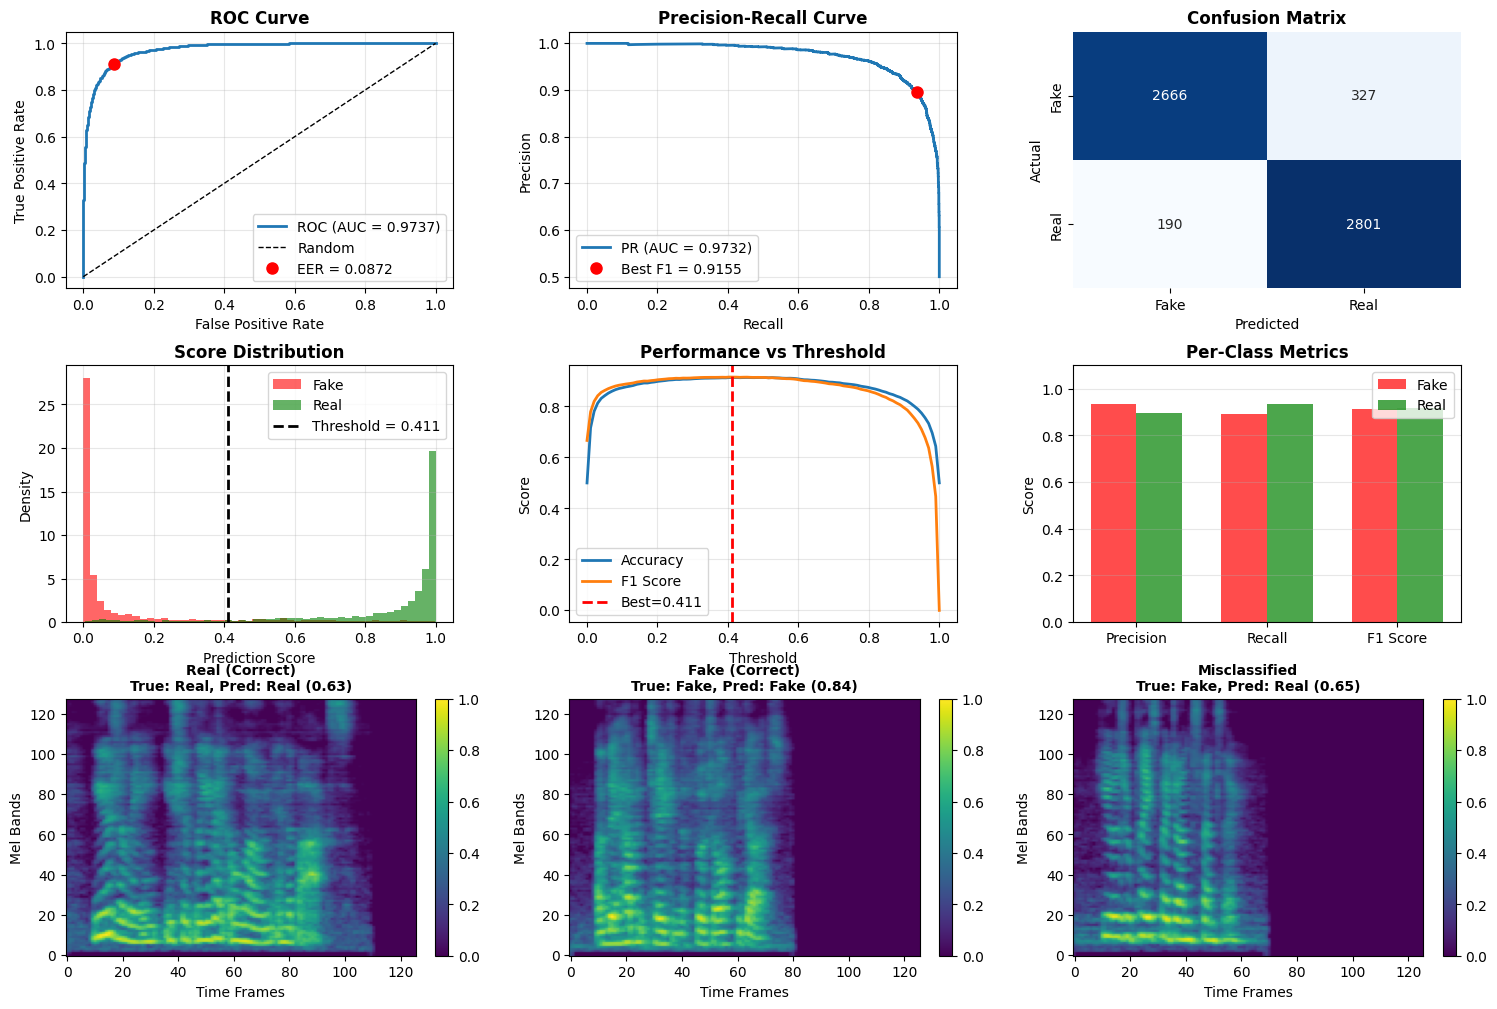

In [ ]:

fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)

# 1. ROC Curve
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(fpr, tpr, linewidth=2, label=f'ROC (AUC = {roc_auc:.4f})')
ax1.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random')
ax1.plot(fpr[eer_threshold_idx], tpr[eer_threshold_idx], 'ro', markersize=8,
         label=f'EER = {eer:.4f}')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('ROC Curve', fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. Precision-Recall Curve
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(recall[:-1], precision[:-1], linewidth=2, label=f'PR (AUC = {pr_auc:.4f})')
ax2.plot(recall[:-1][best_f1_idx], precision[:-1][best_f1_idx], 'ro', markersize=8,
         label=f'Best F1 = {best_f1:.4f}')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.set_title('Precision-Recall Curve', fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

# 3. Confusion Matrix
ax3 = fig.add_subplot(gs[0, 2])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax3, cbar=False,
            xticklabels=['Fake', 'Real'], yticklabels=['Fake', 'Real'])
ax3.set_xlabel('Predicted')
ax3.set_ylabel('Actual')
ax3.set_title('Confusion Matrix', fontweight='bold')

# 4. Score Distribution
ax4 = fig.add_subplot(gs[1, 0])
real_scores = y_pred_probs[y_true == 1]
fake_scores = y_pred_probs[y_true == 0]
ax4.hist(fake_scores, bins=50, alpha=0.6, label='Fake', color='red', density=True)
ax4.hist(real_scores, bins=50, alpha=0.6, label='Real', color='green', density=True)
ax4.axvline(best_f1_threshold, color='black', linestyle='--', linewidth=2,
            label=f'Threshold = {best_f1_threshold:.3f}')
ax4.set_xlabel('Prediction Score')
ax4.set_ylabel('Density')
ax4.set_title('Score Distribution', fontweight='bold')
ax4.legend()
ax4.grid(True, alpha=0.3)

# 5. Threshold vs Metrics
ax5 = fig.add_subplot(gs[1, 1])
threshold_range = np.linspace(0, 1, 100)
accuracies = []
f1s = []
for thresh in threshold_range:
    y_pred_temp = (y_pred_probs >= thresh).astype(int)
    cm_temp = confusion_matrix(y_true, y_pred_temp)
    acc_temp = (cm_temp[0, 0] + cm_temp[1, 1]) / cm_temp.sum()

    if (cm_temp[1, 1] + cm_temp[0, 1]) > 0 and (cm_temp[1, 1] + cm_temp[1, 0]) > 0:
        prec = cm_temp[1, 1] / (cm_temp[1, 1] + cm_temp[0, 1])
        rec = cm_temp[1, 1] / (cm_temp[1, 1] + cm_temp[1, 0])
        f1_temp = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0
    else:
        f1_temp = 0

    accuracies.append(acc_temp)
    f1s.append(f1_temp)

ax5.plot(threshold_range, accuracies, label='Accuracy', linewidth=2)
ax5.plot(threshold_range, f1s, label='F1 Score', linewidth=2)
ax5.axvline(best_f1_threshold, color='red', linestyle='--', linewidth=2,
            label=f'Best={best_f1_threshold:.3f}')
ax5.set_xlabel('Threshold')
ax5.set_ylabel('Score')
ax5.set_title('Performance vs Threshold', fontweight='bold')
ax5.legend()
ax5.grid(True, alpha=0.3)

# 6. Per-class metrics bar chart
ax6 = fig.add_subplot(gs[1, 2])
fake_precision = cm[0, 0] / (cm[0, 0] + cm[1, 0]) if (cm[0, 0] + cm[1, 0]) > 0 else 0
fake_recall = cm[0, 0] / (cm[0, 0] + cm[0, 1]) if (cm[0, 0] + cm[0, 1]) > 0 else 0
fake_f1 = 2 * fake_precision * fake_recall / (fake_precision + fake_recall) if (fake_precision + fake_recall) > 0 else 0

metrics_data = {
    'Precision': [fake_precision, precision_score],
    'Recall': [fake_recall, recall_score],
    'F1 Score': [fake_f1, f1_final]
}
x = np.arange(len(metrics_data))
width = 0.35
ax6.bar(x - width/2, [metrics_data[k][0] for k in metrics_data], width,
        label='Fake', color='red', alpha=0.7)
ax6.bar(x + width/2, [metrics_data[k][1] for k in metrics_data], width,
        label='Real', color='green', alpha=0.7)
ax6.set_ylabel('Score')
ax6.set_title('Per-Class Metrics', fontweight='bold')
ax6.set_xticks(x)
ax6.set_xticklabels(metrics_data.keys())
ax6.legend()
ax6.set_ylim([0, 1.1])
ax6.grid(True, alpha=0.3, axis='y')

# 7-9. Sample spectrograms
for idx, (ax_idx, class_name, class_val) in enumerate([
    (gs[2, 0], 'Real (Correct)', 1),
    (gs[2, 1], 'Fake (Correct)', 0),
    (gs[2, 2], 'Misclassified', None)
]):
    ax = fig.add_subplot(ax_idx)

    if class_val is not None:
        class_indices = np.where((y_true == class_val) & (y_pred == class_val))[0]
    else:
        class_indices = np.where(y_pred != y_true)[0]

    if len(class_indices) > 0:
        sample_idx = np.random.choice(class_indices)
        spec = np.load(test_files[sample_idx])

        im = ax.imshow(spec, aspect='auto', origin='lower', cmap='viridis')
        ax.set_xlabel('Time Frames')
        ax.set_ylabel('Mel Bands')

        true_label = 'Real' if y_true[sample_idx] == 1 else 'Fake'
        pred_label = 'Real' if y_pred[sample_idx] == 1 else 'Fake'
        confidence = y_pred_probs[sample_idx] if y_pred[sample_idx] == 1 else 1 - y_pred_probs[sample_idx]

        title = f'{class_name}\nTrue: {true_label}, Pred: {pred_label} ({confidence:.2f})'
        ax.set_title(title, fontweight='bold', fontsize=10)
        plt.colorbar(im, ax=ax, fraction=0.046)
    else:
        ax.text(0.5, 0.5, f'No {class_name} samples', ha='center', va='center')
        ax.axis('off')

plt.savefig(os.path.join(OUT_DIR, 'comprehensive_evaluation.png'), dpi=300, bbox_inches='tight')
plt.show()



---
## Cell 15: Classification Report

In [ ]:
print("CLASSIFICATION REPORT")

print(classification_report(y_true, y_pred, target_names=['Fake', 'Real'], digits=4))


CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Fake     0.9335    0.8907    0.9116      2993
        Real     0.8955    0.9365    0.9155      2991

    accuracy                         0.9136      5984
   macro avg     0.9145    0.9136    0.9136      5984
weighted avg     0.9145    0.9136    0.9136      5984



In [ ]:

import numpy as np
import librosa
import librosa.display
from tensorflow.keras import models
from google.colab import files
import matplotlib.pyplot as plt

MODEL_PATH = './spectrogram_detection/specrnet_fixed.keras'

print(" AUDIO DEEPFAKE DETECTOR")
print("="*80)
print("\n Upload your audio file...")

uploaded = files.upload()

if uploaded:
    audio_file = list(uploaded.keys())[0]
    print(f"\n Uploaded: {audio_file}")

    print(" Loading model...")
    model = models.load_model(MODEL_PATH)
    print("Model loaded!")

    print(" Processing audio...")
    audio, sr = librosa.load(audio_file, sr=16000, mono=True)
    print(f"   Loaded: {len(audio)} samples ({len(audio)/16000:.2f}s)")

    desired_length = 64000
    if len(audio) < desired_length:
        audio = np.pad(audio, (0, desired_length - len(audio)))
        print(f"   Padded to 4.0s")
    else:
        audio = audio[:desired_length]
        print(f"   Trimmed to 4.0s")


    mel_spec = librosa.feature.melspectrogram(
        y=audio,
        sr=16000,
        n_mels=128,
        n_fft=2048,
        hop_length=512,
        fmin=0,
        fmax=8000
    )

    mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

    print(f"   Spectrogram shape: {mel_spec_db.shape}")
    print(f"   Spectrogram range: [{mel_spec_db.min():.2f}, {mel_spec_db.max():.2f}] dB")

    spec_min = mel_spec_db.min()
    spec_max = mel_spec_db.max()

    if spec_max > spec_min:
        mel_normalized = (mel_spec_db - spec_min) / (spec_max - spec_min)
    else:
        mel_normalized = np.zeros_like(mel_spec_db)

    mel_normalized = np.clip(mel_normalized, 0.0, 1.0)

    print(f"   Normalized range: [{mel_normalized.min():.4f}, {mel_normalized.max():.4f}]")
    print(f"   Normalized mean: {mel_normalized.mean():.4f}")

    mel_input = mel_normalized[np.newaxis, ..., np.newaxis]  # (1, 128, 126, 1)

    print(f"   Final input shape: {mel_input.shape}")


    prediction = model.predict(mel_input, verbose=0)[0][0]


    print("RESULTS")

    print(f"\n RAW SCORE: {prediction:.6f}")
    print(f"   {'   (0.0 = Fake, 1.0 = Real)'}")

    threshold = 0.5
    is_real = prediction >= threshold
    confidence = prediction if is_real else (1 - prediction)

    print(f"\n   VERDICT: {' REAL AUDIO' if is_real else ' FAKE AUDIO'}")
    print(f"   CONFIDENCE: {confidence*100:.2f}%")

    if confidence >= 0.95:
        level = " Very High"
    elif confidence >= 0.85:
        level = " High"
    elif confidence >= 0.70:
        level = " Medium"
    elif confidence >= 0.55:
        level = "Low"
    else:
        level = "Very Low (Uncertain)"

    print(f"   LEVEL: {level}")

    # Detailed interpretation
    print(f"\n   INTERPRETATION:")
    if 0.45 <= prediction <= 0.55:
        print(f"       UNCERTAIN - Score too close to threshold")
        print(f"      The model cannot confidently classify this audio")
    elif prediction >= 0.85:
        print(f"      Strong indicators of REAL audio")
    elif prediction <= 0.15:
        print(f"      Strong indicators of FAKE/DEEPFAKE audio")
    elif is_real:
        print(f"      Likely real, but with moderate confidence")
    else:
        print(f"      Likely fake, but with moderate confidence")


    print("\n DIAGNOSTIC INFO:")
    print(f"   Audio duration: {len(audio)/16000:.2f}s")
    print(f"   Sample rate: 16000 Hz")
    print(f"   Spectrogram shape: {mel_spec_db.shape}")
    print(f"   Normalized to: [0, 1]")
    print(f"   Model input shape: {mel_input.shape}")
    print(f"   Model output: {prediction:.6f}")

    # Check if score is suspiciously extreme
    if prediction > 0.99:
        print(f"\n     WARNING: Score is suspiciously high (>{0.99})")
        print(f"      This might indicate preprocessing mismatch")
    elif prediction < 0.01:
        print(f"\n     WARNING: Score is suspiciously low (<{0.01})")
        print(f"      This might indicate preprocessing mismatch")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

    img1 = librosa.display.specshow(
        mel_spec_db,
        sr=16000,
        hop_length=512,
        x_axis='time',
        y_axis='mel',
        cmap='viridis',
        ax=ax1
    )
    ax1.set_title('Mel Spectrogram (dB scale)', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Time (s)')
    ax1.set_ylabel('Frequency (Hz)')
    fig.colorbar(img1, ax=ax1, format='%+2.0f dB')

    img2 = ax2.imshow(
        mel_normalized,
        aspect='auto',
        origin='lower',
        cmap='viridis',
        extent=[0, 4, 0, 8000]
    )
    ax2.set_title(
        f"{' REAL' if is_real else ' FAKE'} - {confidence*100:.1f}% Confidence",
        fontsize=14,
        fontweight='bold',
        color='green' if is_real else 'red'
    )
    ax2.set_xlabel('Time (s)')
    ax2.set_ylabel('Frequency (Hz)')
    ax2.text(
        2, 7200,
        f'Score: {prediction:.4f}',
        ha='center',
        fontsize=12,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8)
    )
    fig.colorbar(img2, ax=ax2, label='Normalized Intensity')

    plt.tight_layout()
    plt.show()



else:
    print(" No file uploaded!")

In [ ]:


import os

h5_path = os.path.join(OUT_DIR, 'SpecRNet_model.h5')
model.save(h5_path)
print(f" Model saved as .h5: {h5_path}")


try:
    from google.colab import files
    files.download(h5_path)
    print(" Download started!")
except ImportError:
    print(" Not in Colab environment")
    print(f" Model saved at: {h5_path}")
    print("You can download it manually from the file browser")

from IPython.display import FileLink
display(FileLink(h5_path))